# Feature importance: FI / PI / SHAP

Два эксперимента на одних и тех же фичах и одном сплите:
1. **Boosting (XGBoost)**
2. **Random Forest**

Для каждого считаем три оценки важности на **одних и тех же инженерных фичах**
(после `FeatureEngineer` + `ColumnTransformer`):
- **FI** — встроенная важность модели (`feature_importances_`);
- **PI** — permutation importance (`sklearn.inspection.permutation_importance`, на валидации);
- **SHAP** — средняя |SHAP| (TreeExplainer).

Оценки агрегируются по исходным фичам (важности one-hot уровней суммируются).
FE и предобработка берутся из проекта (`src.kaggle_titanic`), чтобы цифры были
сопоставимы с реальными раннами.

## 1. Импорты и настройка

In [1]:
%matplotlib inline
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from scipy.sparse import issparse
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from hydra import compose, initialize_config_dir
from hydra.utils import instantiate

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.kaggle_titanic.data import load_data
from src.kaggle_titanic.pipeline import build_pipeline, resolve_feature_columns

print("project root:", ROOT)

/home/ecnedaced/projects/kaggle-titanic/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


project root: /home/ecnedaced/projects/kaggle-titanic


## 2. Данные и конфиг проекта

Берём ту же FE/предобработку, что и в `main.py`: `feature_set=best`
(base + family + cabin + ticket + identity + bins + frequency),
групповая импутация Age.

In [2]:
with initialize_config_dir(config_dir=str(ROOT / "conf"), version_base="1.3"):
    cfg = compose(config_name="config", overrides=["feature_set=best"])

dataset = load_data(config=cfg, project_root=ROOT)
X, y = dataset.x_train, dataset.y_train

X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, random_state=cfg.seed, stratify=y
)
numeric, categorical, ordinal = resolve_feature_columns(cfg.groups, cfg.feature_set)
print("train:", X_tr.shape, "| val:", X_val.shape)
print("numeric:", numeric)
print("categorical:", categorical)

train: (712, 10) | val: (179, 10)
numeric: ['Age', 'Fare_log', 'SibSp', 'Parch', 'FamilySize', 'IsAlone', 'HasCabin', 'FarePerPerson', 'TicketFreq', 'CabinFreq', 'SurnameFreq']
categorical: ['Sex', 'Embarked', 'Deck', 'TicketPrefix', 'Title']


## 3. Сборка пайплайна и хелперы важности

In [3]:
def make_pipeline(estimator):
    imputer_cfg = cfg.imputation.get("imputer")
    imputer = instantiate(imputer_cfg) if imputer_cfg else None
    encoders = [instantiate(e) for e in cfg.encoding.encoders]
    return build_pipeline(
        numeric, categorical, ordinal,
        estimator=estimator,
        imputer=imputer,
        encoders=encoders,
        scale=cfg.feature_set.scale,
    )


def transformed_df(pipeline, X_raw):
    Xf = pipeline[:-1].transform(X_raw)
    names = pipeline.named_steps["prep"].get_feature_names_out()
    if issparse(Xf):
        Xf = Xf.toarray()
    return pd.DataFrame(Xf, columns=names)


def _source_feature(name):
    body = name.split("__", 1)[1] if "__" in name else name
    for col in categorical:
        if body == col or body.startswith(col + "_"):
            return col
    return body


def _aggregate(series):
    out = {}
    for name, value in series.items():
        src = _source_feature(name)
        out[src] = out.get(src, 0.0) + float(value)
    return pd.Series(out).sort_values(ascending=False)


def feature_importance(pipeline):
    clf = pipeline.named_steps["clf"]
    names = pipeline.named_steps["prep"].get_feature_names_out()
    return _aggregate(pd.Series(clf.feature_importances_, index=names))


def permutation_importance_engineered(pipeline, X_val, y_val):
    Xt = transformed_df(pipeline, X_val)
    clf = pipeline.named_steps["clf"]
    result = permutation_importance(
        clf, Xt.values, y_val, scoring="accuracy", n_repeats=15,
        random_state=cfg.seed, n_jobs=-1,
    )
    return _aggregate(pd.Series(result.importances_mean, index=Xt.columns))


def shap_importance(pipeline, X_val):
    Xt = transformed_df(pipeline, X_val)
    clf = pipeline.named_steps["clf"]
    explainer = shap.TreeExplainer(clf)
    values = explainer.shap_values(Xt, check_additivity=False)
    if isinstance(values, list):
        values = values[1] if len(values) == 2 else values[0]
    elif getattr(values, "ndim", 2) == 3:
        values = values[:, :, 1]
    mean_abs = pd.Series(np.abs(values).mean(axis=0), index=Xt.columns)
    return _aggregate(mean_abs)

## 4. Эксперимент 1 — Boosting (XGBoost)

In [4]:
xgb = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
    random_state=cfg.seed,
)
xgb_pipeline = make_pipeline(xgb)
xgb_pipeline.fit(X_tr, y_tr)
print("val accuracy:", round(xgb_pipeline.score(X_val, y_val), 4))

xgb_results = pd.DataFrame({
    "FI": feature_importance(xgb_pipeline),
    "PI": permutation_importance_engineered(xgb_pipeline, X_val, y_val),
    "SHAP": shap_importance(xgb_pipeline, X_val),
}).fillna(0.0)
display(xgb_results.head(15))

val accuracy: 0.7765


,FI,PI,SHAP
Age,0.014231,3.873371e-02,0.607998
AgeBin,0.013509,-2.011173e-02,0.097404
CabinFreq,0.014736,1.638734e-02,0.200631
Deck,0.074553,-5.586592e-03,0.187738
Embarked,0.040194,-5.214153e-03,0.419114
FamilySize,0.039403,-1.452514e-02,0.104986
FareBin,0.008673,0.000000e+00,0.014710
FarePerPerson,0.016590,-1.266294e-02,0.545706
Fare_log,0.014409,7.401487e-18,0.518977
HasCabin,0.042877,2.234637e-03,0.105921


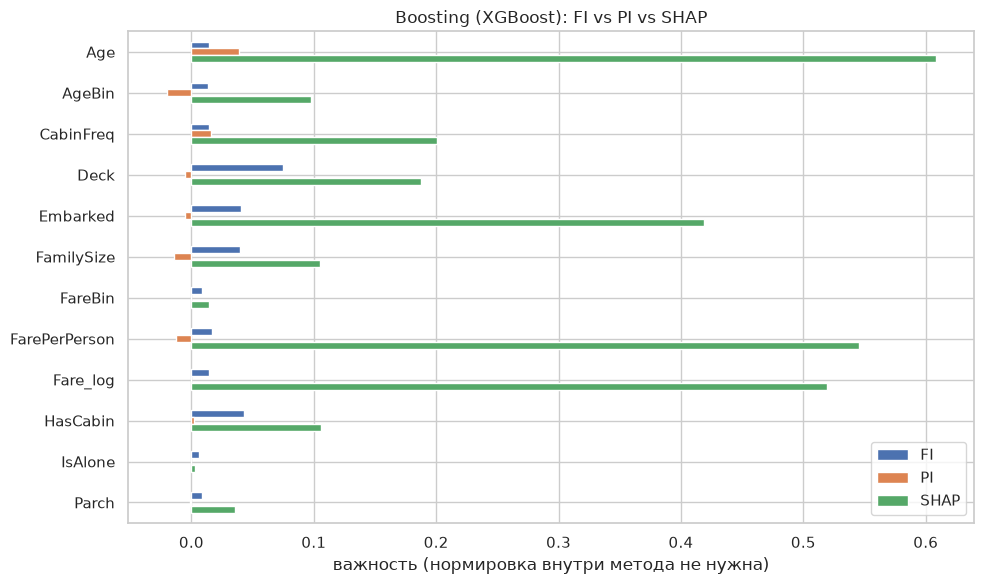

In [5]:
xgb_results.head(12).plot.barh(figsize=(10, 6))
plt.gca().invert_yaxis()
plt.title("Boosting (XGBoost): FI vs PI vs SHAP")
plt.xlabel("важность (нормировка внутри метода не нужна)")
plt.tight_layout()
plt.show()

## 5. Эксперимент 2 — Random Forest

In [6]:
rf = RandomForestClassifier(n_estimators=300, random_state=cfg.seed)
rf_pipeline = make_pipeline(rf)
rf_pipeline.fit(X_tr, y_tr)
print("val accuracy:", round(rf_pipeline.score(X_val, y_val), 4))

rf_results = pd.DataFrame({
    "FI": feature_importance(rf_pipeline),
    "PI": permutation_importance_engineered(rf_pipeline, X_val, y_val),
    "SHAP": shap_importance(rf_pipeline, X_val),
}).fillna(0.0)
display(rf_results.head(15))

val accuracy: 0.7933


,FI,PI,SHAP
Age,0.122111,0.023836,0.024696
AgeBin,0.037297,0.010056,0.014602
CabinFreq,0.023420,-0.011173,0.020418
Deck,0.043640,-0.005587,0.032148
Embarked,0.028401,-0.024209,0.023511
FamilySize,0.028075,-0.007076,0.011079
FareBin,0.029933,-0.011546,0.012580
FarePerPerson,0.100624,-0.016760,0.038699
Fare_log,0.088269,-0.026443,0.025119
HasCabin,0.013996,-0.004842,0.016114


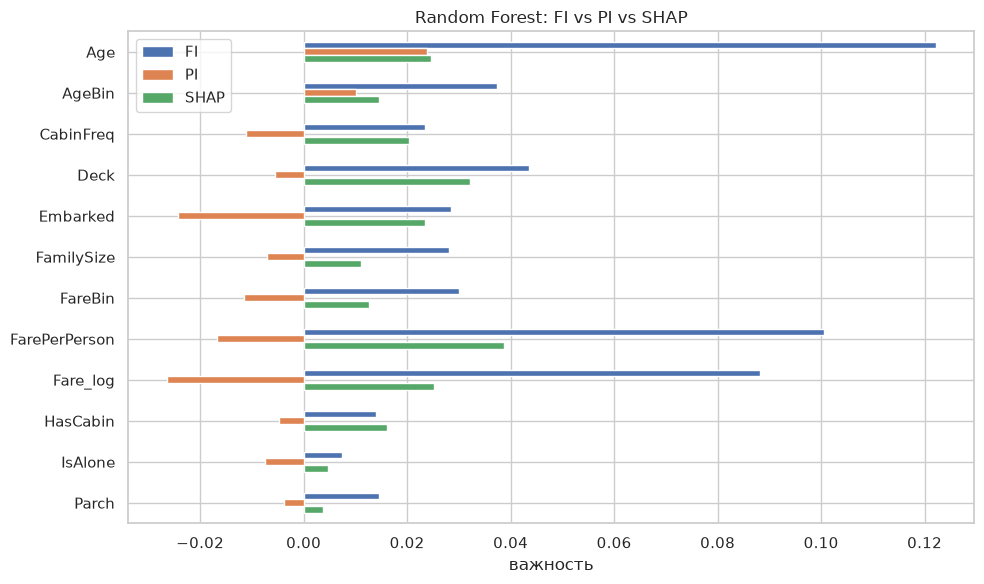

In [7]:
rf_results.head(12).plot.barh(figsize=(10, 6))
plt.gca().invert_yaxis()
plt.title("Random Forest: FI vs PI vs SHAP")
plt.xlabel("важность")
plt.tight_layout()
plt.show()

## 6. Сравнение FI двух моделей (XGBoost vs RF)

,XGBoost FI,RF FI
Title,0.348966,0.143726
Sex,0.117610,0.158262
TicketPrefix,0.104864,0.045960
Pclass,0.080274,0.033991
Deck,0.074553,0.043640
HasCabin,0.042877,0.013996
Embarked,0.040194,0.028401
FamilySize,0.039403,0.028075
TicketFreq,0.027394,0.029524
FarePerPerson,0.016590,0.100624


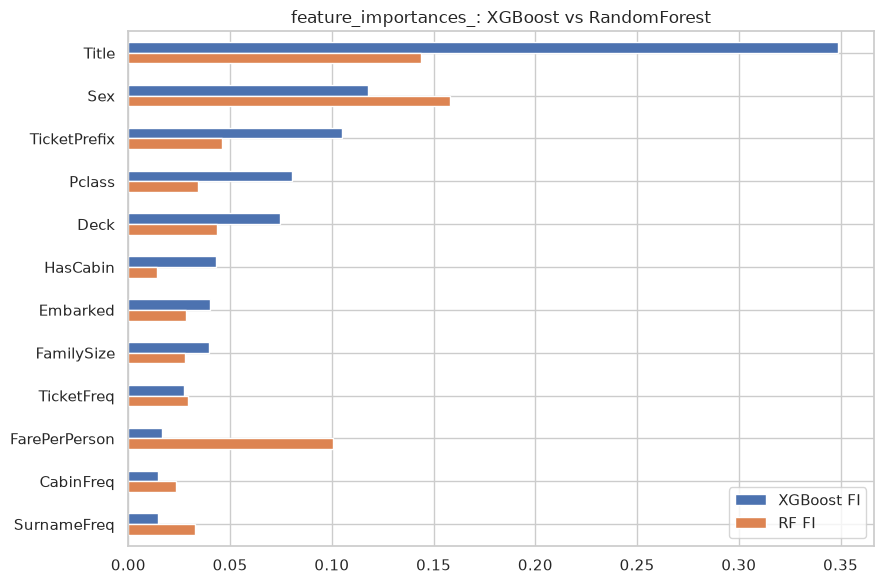

In [8]:
fi_compare = pd.DataFrame({
    "XGBoost FI": xgb_results["FI"],
    "RF FI": rf_results["FI"],
}).fillna(0.0).sort_values("XGBoost FI", ascending=False)
display(fi_compare.head(15))

fi_compare.head(12).plot.barh(figsize=(9, 6))
plt.gca().invert_yaxis()
plt.title("feature_importances_: XGBoost vs RandomForest")
plt.tight_layout()
plt.show()

## 7. Заметки

- **FI** — быстрая, но biased: у деревьев завышает важность
  высококардинальных/непрерывных признаков, считается на train-фите.
- **PI** — честнее (перестановка на валидации), но зависит от корреляций:
  если фичи дублируют друг друга, важность «размазывается».
- **SHAP** — аддитивные вклады, тоже на валидации; для one-hot уровни
  агрегированы в исходную фичу (сумма |SHAP|).
- Все три считаются на **одних и тех же инженерных фичах**, поэтому строки
  сопоставимы; на разных методах абсолютные масштабы разные — сравнивай
  порядок и топ, а не точные значения.
- PI и SHAP здесь — на holdout-валидации, а не в CV (для стабильности можно
  усреднять по фолдам).